# Running a simulation: spin-1 transverse-field Ising model

This notebook implements the documentation page **Running a simulation** for a chain of spin-1.

In [1]:
import os

import jax
import numpy as np
from pygfmc.hamiltonian import Spin, chain, exact_diagonalization


print(f'JAX version : {jax.__version__}')
print(f'Backend     : {jax.default_backend()}')

JAX version : 0.9.2
Backend     : cpu


## Hamiltonian and walkers


The Hamiltonian is the spin-1 transverse-field Ising chain, in spin-1 operators

$$
H = -J \sum_{i} S^z_i S^z_{i+1} - h \sum_i S^x_i\,,
\qquad J = 1\,,\quad h = h_c = 1.326\,,
$$

at its critical point $h_c$, see [C. West, A. Garcia-Saez and T.-C. Wei, Phys. Rev. B **92**, 115103 (2015)](https://journals.aps.org/prb/abstract/10.1103/PhysRevB.92.115103).

`Spin` writes the transverse field as $-h_{\pm} \sum_i (S^+_i + S^-_i) = -2 h_{\pm} \sum_i S^x_i$, so the couplings
are `J_z=-1` and `h_pm=h/2`.

In [2]:
L = 12
lattice = chain(L)
h_c = 1.326
H = Spin.create(lattice.edges, S=1.0, J_z=-1.0, h_pm=h_c / 2)

E0 = exact_diagonalization(H)[0][0]    # exact reference for small systems (3^12 states)

## Walkers

Walkers are randomly generated, with the values $x_i \in \{-1, 0, 1\}$ on each site.

In [3]:
from pygfmc.walkers import prepare_walkers_random

walkers = prepare_walkers_random(1024, L, jax.random.PRNGKey(0), states=(-1.0, 0.0, 1.0))

## Guiding wavefunction

We use a Jastrow wavefunction for spin-1 configurations:

$$
\psi_T(x) = \exp\Big( -\beta \sum_{(i,j)} x_i x_j - d \sum_i x_i^2 \Big)\,,
$$
where the sum runs over the given edges. A negative $\beta < 0$ favors a ferromagnetic ground state, and $d$ weights the
value $x_i = 0$ against $x_i = \pm 1$.

In [4]:
from pygfmc.wavefunction import JastrowSpin, train_with_netket, make_hilbert
os.environ["NETKET_NO_TIPS"] = "1"   # silence NetKet's tips
import netket as nk

guide = JastrowSpin(L, lattice.edges, beta=-0.1, d=0.0)

# the transverse field changes single spins: sample with single-site updates, on the
# local states (-1, 0, 1) of the Spin class (NetKet's own spin-1 space uses 2m instead)
sampler = nk.sampler.MetropolisLocal(make_hilbert(H.local_hilbert_space, L))
guide, history = train_with_netket(H, guide, sampler=sampler, return_history=True)

print(f'beta = {float(guide.beta[0]):.4f}, d = {float(guide.d[0]):.4f}')
print(f'variational energy: {history[0]:.5f} (beta = -0.1, d = 0) -> {np.mean(history[-10:]):.5f} (trained)')

beta = -0.4634, d = 0.2774
variational energy: -15.82197 (beta = -0.1, d = 0) -> -17.39052 (trained)


## Observables

We measure the nearest-neighbor correlator $\sum_iS^z_iS^z_{i+1}$ (diagonal) and the transverse magnetization $\sum_iS^x_i$ (off-diagonal).

In [5]:
# nearest-neighbor correlator sum_i S^z_i S^z_i+1: diagonal
zz = Spin.create(lattice.edges, S=1.0, J_z=1.0)

# transverse magnetization sum_i S^x_i = 0.5 sum_i (S^+_i + S^-_i) = -h_pm sum_i (S^+_i + S^-_i) with h_pm = -0.5
Sx = Spin.create([], S=1.0, N=L, h_pm=-0.5, sign_check=False)

diag_operators     = {"ZZ": zz}
off_diag_operators = {"Sx": Sx}

# exact references for small systems
E_ed, diag_ex, off_ex = exact_diagonalization(H, diag_operators=diag_operators, off_diag_operators=off_diag_operators)
E0 = E_ed[0]    # reuse the same eigensolve for energy and observables

print('ED diagonal:',diag_ex)
print('ED off-diagonal:',off_ex)

ED diagonal: {'ZZ': array([5.30762156])}
ED off-diagonal: {'Sx': array([9.24864507])}


## Run GFMC

The `run` function combines all elements above and executes the simulation:

In [6]:
from pygfmc import run

walkers, energy, obs, stats, raw = run(
    walkers, 1000, H, step_size=0.5, guide=guide,
    p_array=[4, 8, 16, 32, 64], rng_key=jax.random.PRNGKey(1),
    warmup_steps=500, verbosity=8,
    diag_operators=diag_operators, off_diag_operators=off_diag_operators,
    off_diag_stride=4, number_of_outputs=5
)
print("GFMC energy: ",energy, "; exact:", E0)                      # energy[p] for every window p
print("GFMC Sx: ", obs["Sx"], "; exact:", off_ex["Sx"])        # obs[name][p], and the exact value
print("GFMC Zz: ", obs["ZZ"], "; exact:", diag_ex["ZZ"])           # obs[name][p], and the exact value

[gfmc] - [run_warmup 1/4] - step=0.0625, 125 steps @ 21.6 it/s, avg_log_weight = 17.532434


[gfmc] - [run_warmup 2/4] - step=0.125, 125 steps @ 30.4 it/s, avg_log_weight = 17.568537


[gfmc] - [run_warmup 3/4] - step=0.25, 125 steps @ 28.4 it/s, avg_log_weight = 17.570799


[gfmc] - [run_warmup 4/4] - step=0.5, 125 steps @ 24.8 it/s, avg_log_weight = 17.570227


[estimators] - [check_off_diag_operator_positivity] - all operators passed positivity check (100 configs, 1 operators)


...

[gfmc] - [run_gfmc] - step: 400/1000, 5.9 it/s, N_config = 912/1024 (89.1%) Energy[p]: {4: -17.56865256759808, 8: -17.569010534812247, 16: -17.56930418479155, 32: -17.569298404469954, 64: -17.569457718316784}
[gfmc] - [run_gfmc] - operators: {'ZZ': {4: 4.733019807413249, 8: 4.973075279843588, 16: 5.195899217052233, 32: 5.291887908358158, 64: 5.3120278274920905}, 'Sx': {4: 9.695240349920951, 8: 9.528050749899935, 16: 9.417434292374416, 32: 9.482582484684382, 64: 9.784030323280637}}


[gfmc] - [run_gfmc] - step: 600/1000, 5.8 it/s, N_config = 893/1024 (87.2%) Energy[p]: {4: -17.569039840646237, 8: -17.569289062772924, 16: -17.569483819267745, 32: -17.56956712962569, 64: -17.569626791522925}
[gfmc] - [run_gfmc] - operators: {'ZZ': {4: 4.740470553986784, 8: 4.980826619475109, 16: 5.20427664530148, 32: 5.301223307306332, 64: 5.285185068163806}, 'Sx': {4: 9.69389078267133, 8: 9.525861761371733, 16: 9.383931777886378, 32: 9.361837333543214, 64: 9.543147796091512}}


[gfmc] - [run_gfmc] - step: 800/1000, 5.8 it/s, N_config = 883/1024 (86.2%) Energy[p]: {4: -17.56896941795538, 8: -17.569152379318346, 16: -17.569287878886247, 32: -17.569356373588914, 64: -17.569352475827717}
[gfmc] - [run_gfmc] - operators: {'ZZ': {4: 4.741787268446387, 8: 4.981886401269649, 16: 5.203314294159549, 32: 5.2897132095724135, 64: 5.288298276853449}, 'Sx': {4: 9.685678683809071, 8: 9.51278512362397, 16: 9.382634511467305, 32: 9.374953308189923, 64: 9.559513753969478}}


[gfmc] - [run_gfmc] - step: 1000/1000, 5.8 it/s, N_config = 907/1024 (88.6%) Energy[p]: {4: -17.569199579983724, 8: -17.56936920208184, 16: -17.569496056048433, 32: -17.569537276576, 64: -17.56949131665609}
[gfmc] - [run_gfmc] - operators: {'ZZ': {4: 4.7417149441962945, 8: 4.981732320836661, 16: 5.2025394654855734, 32: 5.2913894569535085, 64: 5.304560013592511}, 'Sx': {4: 9.683576381863316, 8: 9.502988434021303, 16: 9.360729534614096, 32: 9.325059838118415, 64: 9.501202305548803}}


[estimators] - [statistics] - 10 branching steps (+22 lineage-only)
[estimators] - [statistics] - N_walkers: 1024
[estimators] - [statistics] - step_size: 0.5
[estimators] - [statistics] - lam: not used
[estimators] - [statistics] - avg_log_weight: 17.570227
[estimators] - [statistics] - unique (pre): 908.8 ± 6.7  (88.8%)
[estimators] - [statistics] - unique (post): 906.4 ± 10.2  (88.5%)
[estimators] - [statistics] - H_diag: min=-12.0000, max=4.0000  (observed max over the 10 health steps)
[estimators] - [statistics] - escape rate: min=5.8778, max=22.7943
[estimators] - [statistics] - hops per branching step (Gamma*step_size): mean=6.608, max=11.397
[estimators] - [statistics] - escape rate Gamma: mean=13.216, min=5.878, max=22.794
[estimators] - [statistics] - hold time (a draw of 1/Gamma, not hops per step): mean=0.0786, max=0.8637
[estimators] - [statistics] - changed (per-index): 100.0% avg over 10 steps
[estimators] - [statistics] - overlap (pop):       5.1% avg over 10 steps
[est

In [7]:
from pygfmc import evaluate_observables

# Point estimates for every window p.  Error bars come from a blocked jackknife
# (n_blocks=...), whose blocks must be longer than the largest window p = 64 and
# the autocorrelation time; 1000 steps cannot give 20 such blocks, so the errors
# are computed below, once the chain has been extended.
E, O = evaluate_observables(raw)
print("GFMC energy: ", E)


GFMC energy:  {4: -17.56920034015075, 8: -17.56936920782467, 16: -17.56949531588155, 32: -17.56953811565986, 64: -17.56949133119719}


## Storing and resuming a calculation

Simulations can be stored and resumed from disk:

In [8]:
from pygfmc import write_to_HDF5, run_from_HDF5, load_raw_from_HDF5

if os.path.exists("tfim_spin1.h5"):         # start a fresh file: a file refuses the same run twice
    os.remove("tfim_spin1.h5")
write_to_HDF5("tfim_spin1.h5", stats, walkers=walkers, energy=energy, obs=obs, raw=raw)

for block in range(3):                      # three more blocks of 2000 steps
    walkers, energy, obs, stats, raw = run_from_HDF5(
        "tfim_spin1.h5", H, guide=guide, n_steps=2000,
        diag_operators=diag_operators, off_diag_operators=off_diag_operators,
        verbosity=0,
    )
    write_to_HDF5("tfim_spin1.h5", stats, walkers=walkers, energy=energy, obs=obs, raw=raw)

# estimates and error bars from the whole chain in the file: 7000 steps in
# 20 blocks of 350 steps, longer than p = 64 and the autocorrelation time
E, O, E_err, O_err = evaluate_observables(load_raw_from_HDF5("tfim_spin1.h5"), n_blocks=20)

[write_to_HDF5] wrote tfim_spin1.h5:/run_0


[write_to_HDF5] wrote tfim_spin1.h5:/run_1


[write_to_HDF5] wrote tfim_spin1.h5:/run_2


[write_to_HDF5] wrote tfim_spin1.h5:/run_3


## Convergence with the projection depth

Each window $p$ projects both sides of the estimate by $\tau = p\,\beta_\mathrm{imag}/2$. The energy, the correlator and the transverse magnetization converge to the exact values as $\tau$ grows.

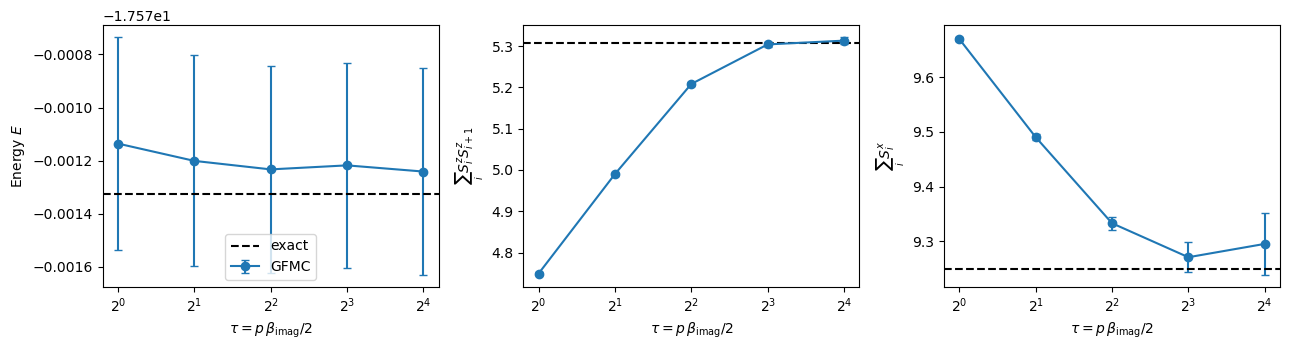

In [9]:
import matplotlib.pyplot as plt

step_size = 0.5
ps  = sorted(E)
tau = np.array(ps) * step_size / 2

panels = [("Energy $E$",                 E,          E_err,          E0),
          (r"$\sum_i S^z_iS^z_{i+1}$",   O["ZZ"],    O_err["ZZ"],    diag_ex["ZZ"][0]),
          (r"$\sum_i S^x_i$",            O["Sx"],  O_err["Sx"],  off_ex["Sx"][0])]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (label, val, err, exact) in zip(axes, panels):
    ax.errorbar(tau, [val[p] for p in ps], yerr=[err[p] for p in ps],
                fmt="o-", capsize=3, label="GFMC")
    ax.axhline(exact, color="k", ls="--", label="exact")
    ax.set_xscale("log", base=2)
    ax.set_xlabel(r"$\tau = p\,\beta_\mathrm{imag}/2$")
    ax.set_ylabel(label)
axes[0].legend()
plt.tight_layout()
plt.show()

## Tuning the step size

The code of *Tuning the step size* in *Running a good simulation*: starting from the equilibrated walkers, one `statistics` call per step size $\beta$ records the effective sample size $n_\mathrm{eff}$ at every projection depth $\tau = p\beta/2$. The best $\beta$ gives the largest $n_\mathrm{eff}$ at the target $\tau$.

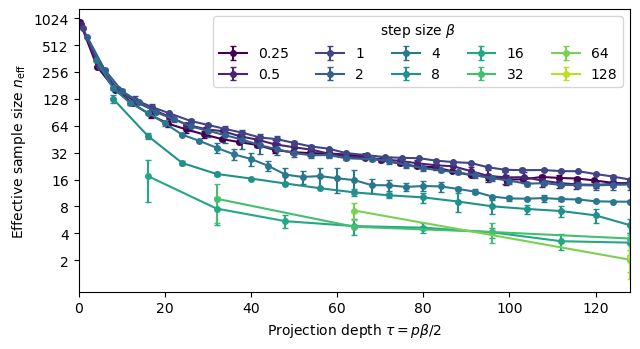

In [10]:
import matplotlib.pyplot as plt
from pygfmc import statistics

tau_max = 128.0                                      # target projection depth
betas   = [0.25, 0.5, 1, 2, 4, 8, 16, 32, 64, 128]  # step sizes to compare
seeds   = range(2)                                   # independent repetitions
colors  = plt.cm.viridis(np.linspace(0, 0.9, len(betas)))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for beta, color in zip(betas, colors):
    m_max   = round(tau_max / beta)
    m_array = np.unique(np.linspace(1, m_max, 32).round().astype(int))
    n_eff   = np.array([
        statistics(walkers, H, guide=guide,
                   avg_log_weight=stats["avg_log_weight"], step_size=beta,
                   method="cont_time", rng_key=jax.random.PRNGKey(seed),
                   m_array=m_array, quiet=True)[1]["effective_sample_size"]
        for seed in seeds])
    tau = m_array * beta                             # tau = (p/2) * beta = m * beta
    ax.errorbar(tau, n_eff.mean(axis=0),
                yerr=n_eff.std(axis=0, ddof=1) / np.sqrt(len(seeds)),
                fmt="o-", ms=4, capsize=2, color=color, label=f"{beta:g}")

ax.set_xlabel(r"Projection depth $\tau = p\beta/2$")
ax.set_ylabel(r"Effective sample size $n_\mathrm{eff}$")
ax.set_yscale("log")
ax.set_yticks([2**k for k in range(1, 11)], [str(2**k) for k in range(1, 11)])
ax.minorticks_off()
ax.set_xlim(0, tau_max)
ax.legend(title=r"step size $\beta$", loc="upper right", ncol=5)
fig.tight_layout()
plt.show()